# LeafLens — Part 1: Setup, Data, Preprocessing
Runtime → Change runtime type → **T4 GPU** before running.

## 1. Environment

In [1]:
!pip install -q kaggle scikit-learn matplotlib
import torch, torchvision
print(torch.__version__, torchvision.__version__, "| GPU:", torch.cuda.is_available())

2.11.0+cu130 0.26.0+cu130 | GPU: True


## 2. Download PlantVillage (needs kaggle.json from Kaggle → Settings → Create New Token)

In [2]:
from google.colab import files
files.upload()  # select kaggle.json
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d abdallahalidev/plantvillage-dataset -p data --unzip -q

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0


## 3. Index images + class counts

In [3]:
from pathlib import Path
from collections import Counter

EXTS = {".jpg", ".jpeg", ".png"}
root = next(p for p in Path("data").rglob("color") if p.is_dir())
classes = sorted(d.name for d in root.iterdir() if d.is_dir())
class_to_idx = {c: i for i, c in enumerate(classes)}

paths, labels = [], []
for c in classes:
    for f in (root / c).iterdir():
        if f.suffix.lower() in EXTS:
            paths.append(str(f)); labels.append(class_to_idx[c])

print(root, "|", len(classes), "classes |", len(paths), "images")
for c, n in sorted(Counter(classes[l] for l in labels).items(), key=lambda x: x[1]):
    print(f"{n:6d}  {c}")

data/plantvillage dataset/color | 38 classes | 54305 images
   152  Potato___healthy
   275  Apple___Cedar_apple_rust
   360  Peach___healthy
   371  Raspberry___healthy
   373  Tomato___Tomato_mosaic_virus
   423  Grape___healthy
   456  Strawberry___healthy
   513  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
   621  Apple___Black_rot
   630  Apple___Apple_scab
   854  Cherry_(including_sour)___healthy
   952  Tomato___Leaf_Mold
   985  Corn_(maize)___Northern_Leaf_Blight
   997  Pepper,_bell___Bacterial_spot
  1000  Potato___Early_blight
  1000  Potato___Late_blight
  1000  Tomato___Early_blight
  1052  Cherry_(including_sour)___Powdery_mildew
  1076  Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
  1109  Strawberry___Leaf_scorch
  1162  Corn_(maize)___healthy
  1180  Grape___Black_rot
  1192  Corn_(maize)___Common_rust_
  1383  Grape___Esca_(Black_Measles)
  1404  Tomato___Target_Spot
  1478  Pepper,_bell___healthy
  1502  Blueberry___healthy
  1591  Tomato___healthy
  1645  Appl

## 4. Stratified 70/15/15 split (done BEFORE augmentation, so no leakage)

In [4]:
import json, os
from sklearn.model_selection import train_test_split

SEED = 42
tr_p, tmp_p, tr_y, tmp_y = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
va_p, te_p, va_y, te_y = train_test_split(tmp_p, tmp_y, test_size=0.50, stratify=tmp_y, random_state=SEED)
print("train/val/test:", len(tr_p), len(va_p), len(te_p))

os.makedirs("leaflens", exist_ok=True)
json.dump({"classes": classes, "train": [tr_p, tr_y], "val": [va_p, va_y], "test": [te_p, te_y]},
          open("leaflens/splits.json", "w"))

train/val/test: 38013 8146 8146


## 5. Transforms, Dataset, DataLoaders

In [5]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet stats (needed for pretrained ResNet-50)

train_tf = T.Compose([
    T.RandomResizedCrop(224, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(20),
    T.ColorJitter(0.2, 0.2, 0.2),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(), T.Normalize(MEAN, STD)])

class LeafDS(Dataset):
    def __init__(self, paths, labels, tf):
        self.paths, self.labels, self.tf = paths, labels, tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

BS = 64
train_dl = DataLoader(LeafDS(tr_p, tr_y, train_tf), BS, shuffle=True, num_workers=2, pin_memory=True)
val_dl = DataLoader(LeafDS(va_p, va_y, eval_tf), BS, num_workers=2, pin_memory=True)
test_dl = DataLoader(LeafDS(te_p, te_y, eval_tf), BS, num_workers=2, pin_memory=True)

## 6. Class weights (used in the loss in the training step)

In [6]:
import numpy as np

cnt = np.bincount(tr_y, minlength=len(classes))
class_weights = torch.tensor(cnt.sum() / (len(classes) * cnt), dtype=torch.float)
print("class weight range: %.2f - %.2f" % (class_weights.min().item(), class_weights.max().item()))

class weight range: 0.26 - 9.44


## 7. Sanity checks

batch: (64, 3, 224, 224) (64,) | mean -0.14 std 1.03


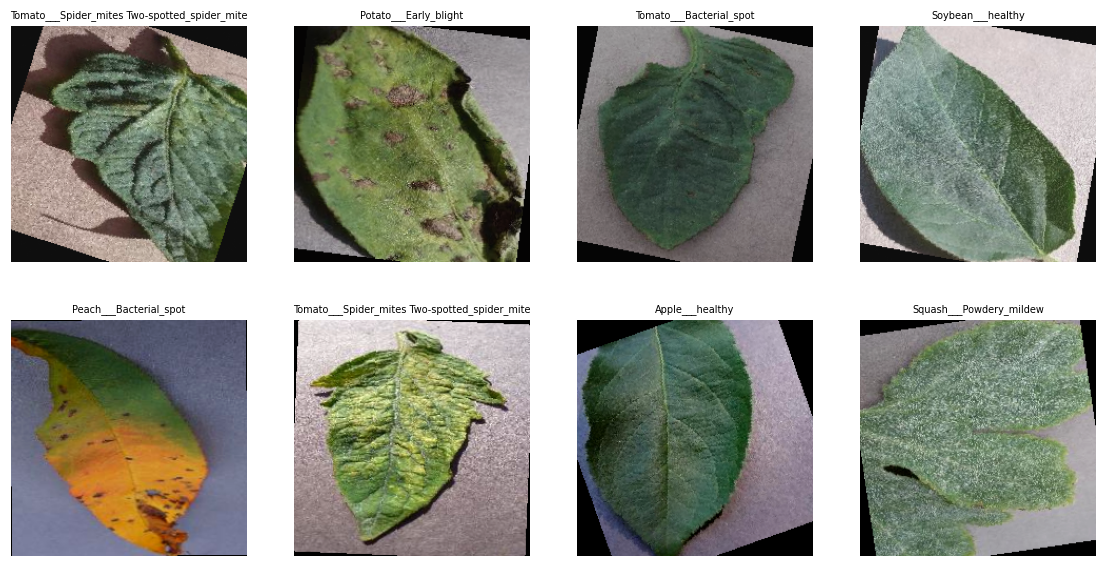

In [7]:
import matplotlib.pyplot as plt

assert not ((set(tr_p) & set(va_p)) | (set(tr_p) & set(te_p)) | (set(va_p) & set(te_p))), "split leakage!"
assert all(len(set(y)) == len(classes) for y in (tr_y, va_y, te_y)), "class missing from a split"

x, y = next(iter(train_dl))
print("batch:", tuple(x.shape), tuple(y.shape), "| mean %.2f std %.2f" % (x.mean().item(), x.std().item()))

def show(x, y, n=8):
    x = (x[:n] * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1)
    fig, ax = plt.subplots(2, n // 2, figsize=(14, 7))
    for a, im, l in zip(ax.flat, x, y[:n]):
        a.imshow(im.permute(1, 2, 0)); a.set_title(classes[l], fontsize=7); a.axis("off")
    plt.show()

show(x, y)